# Simulasi Reinforcement Learning: Pengelolaan Keuangan & Kehidupan Harian Mahasiswa (30 Hari, 5 Step/Hari)

Notebook ini menjalankan pelatihan, evaluasi berkala, penyimpanan checkpoint terbaik, dan pencatatan eksperimen yang **reproducible** untuk `StudentLifeEnv` (150 step/bulan, 1 saldo operasional tunggal Rp 1.465.000, fitur bekal, masak pagi berat, dan tidur otomatis) menggunakan `MaskablePPO` (`StudentPPOAgent`).

In [15]:
from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
import stable_baselines3
import sb3_contrib

from src.env import StudentLifeEnv
from src.agents import StudentPPOAgent, set_global_seed

print(f"Python/Torch: {torch.__version__} | CUDA: {torch.cuda.is_available()}")
print(
    f"Gymnasium: {gym.__version__} | SB3: {stable_baselines3.__version__} | "
    f"SB3-Contrib: {sb3_contrib.__version__}"
)

Python/Torch: 2.15.0+cpu | CUDA: False
Gymnasium: 1.4.0 | SB3: 2.9.2 | SB3-Contrib: 2.9.2


## 1. Konfigurasi Eksperimen & Validasi Environment

In [16]:
ENV_CONFIG_PATH = "env_config.yaml"
EXPERIMENT_NAME = "maskable_ppo_5step_unified_budget"
RUNS_ROOT_DIR = "runs"

TRAIN_CONFIG = {
    "seed": 42,
    "num_environments": 4,
    "features_dim": 128,
    "hidden_dim": 128,
    "policy_hidden_layers": [128, 128],
    "value_hidden_layers": [128, 128],
    "learning_rate": 3e-4,
    "rollout_steps_per_env": 300,       # 300 * 4 env = 1.200 step (8 episode penuh) per update
    "batch_size": 64,
    "num_epochs": 10,
    "discount_factor_gamma": 0.99,
    "gae_lambda": 0.95,
    "clip_range": 0.2,
    "entropy_coefficient": 0.015,
    "use_action_masking": True,         # MaskablePPO (sb3-contrib)
    "device": "auto",
}

TRAINING_SCHEDULE = {
    "total_timesteps": 250_000,
    "eval_interval_steps": 25_000,
    "eval_episodes": 10,
    "final_eval_episodes": 20,
    "eval_seed": 1000,
}

with open(ENV_CONFIG_PATH, "r", encoding="utf-8") as config_file:
    active_env_config = yaml.safe_load(config_file)

sample_env = StudentLifeEnv(yaml_path=ENV_CONFIG_PATH)
print("Observation space:", sample_env.observation_space)
print("Action space:", sample_env.action_space, "| total mask logits:", sample_env.action_masks().shape[0])
print(
    "Budget bulanan:",
    f"Rp {active_env_config['finance']['monthly_budget']:,.0f}",
    "| Kuota:",
    f"Rp {active_env_config['finance']['fixed_expenses']['mobile_data']:,.0f}",
    "| Saldo operasional tunggal:",
    f"Rp {active_env_config['finance']['initial_operational_budget']:,.0f}",
)

Observation space: Box(0.0, inf, (35,), float32)
Action space: MultiDiscrete([8 2 3 3 3 3 8 2 2 2 2]) | total mask logits: 38
Budget bulanan: Rp 1,500,000 | Kuota: Rp 35,000 | Saldo operasional tunggal: Rp 1,465,000


## 2. Training Loop Reproducible & Best-Model Checkpointing

In [17]:
set_global_seed(TRAIN_CONFIG["seed"])

agent = StudentPPOAgent(
    yaml_path=ENV_CONFIG_PATH,
    **TRAIN_CONFIG,
    verbose=0,
)

run_result = agent.train_with_logging(
    **TRAINING_SCHEDULE,
    experiment_name=EXPERIMENT_NAME,
    runs_root_dir=RUNS_ROOT_DIR,
    progress_bar=False,
)

run_dir = Path(run_result["run_dir"])
eval_history_df = run_result["eval_history_df"]
final_summary = run_result["final_summary"]
final_episodes_df = run_result["final_episodes_df"]
best_episode_trace_df = run_result["best_episode_trace_df"]

print(f"\nRun selesai. Direktori artefak: {run_dir}")
print(f"Best checkpoint pada timestep: {run_result['best_checkpoint_timestep']:,}")
print(
    f"Episode evaluasi terbaik: episode {final_summary['best_eval_episode_index']} "
    f"(seed {final_summary['best_eval_episode_seed']}, reward {final_summary['max_episode_reward']:.2f})"
)

Step   25200/250000 | Reward:  212.56 +/- 40.86 | Complete:   0.0% | Kelas:  98.1% | Sisa: Rp     1,722 | Masak/Bekal:  0.0 [BEST]
Step   50400/250000 | Reward:  229.90 +/- 52.67 | Complete:   0.0% | Kelas:  93.6% | Sisa: Rp       848 | Masak/Bekal:  0.0 [BEST]
Step   75600/250000 | Reward:  245.71 +/- 54.17 | Complete:   0.0% | Kelas:  93.8% | Sisa: Rp     1,418 | Masak/Bekal:  0.0 [BEST]
Step  100800/250000 | Reward:  257.86 +/- 44.72 | Complete:   0.0% | Kelas:  96.7% | Sisa: Rp       920 | Masak/Bekal:  0.0 [BEST]
Step  126000/250000 | Reward:  205.48 +/- 96.14 | Complete:   0.0% | Kelas:  90.8% | Sisa: Rp     1,301 | Masak/Bekal:  0.0
Step  151200/250000 | Reward:  228.36 +/- 23.45 | Complete:   0.0% | Kelas:  95.8% | Sisa: Rp     2,666 | Masak/Bekal:  0.0
Step  176400/250000 | Reward:  236.80 +/- 53.49 | Complete:   0.0% | Kelas:  95.2% | Sisa: Rp     2,091 | Masak/Bekal:  0.0
Step  201600/250000 | Reward:  228.30 +/- 50.04 | Complete:   0.0% | Kelas:  95.6% | Sisa: Rp     2,188 

## 3. Ringkasan Metrik Evaluasi & Alokasi Anggaran 1 Bulan (Best Checkpoint)

In [18]:
summary_table = pd.DataFrame(
    list(final_summary.items()),
    columns=["metric", "value"],
)
display(summary_table)

# Tabel alokasi pengeluaran 1 bulan (pedoman distribusi budget hasil RL)
initial_budget = float(active_env_config["finance"]["initial_operational_budget"])
allocation_rows = [
    ("transport", final_summary["mean_spent_transport_idr"]),
    ("grocery_cooking", final_summary["mean_spent_grocery_idr"]),
    ("external_food_warung_snack", final_summary["mean_spent_external_food_idr"]),
    ("cafe", final_summary["mean_spent_cafe_idr"]),
    ("minimarket_impulse", final_summary["mean_spent_minimarket_impulse_idr"]),
    ("remaining_balance", final_summary["mean_final_balance_idr"]),
]
allocation_df = pd.DataFrame(allocation_rows, columns=["category", "mean_idr"])
allocation_df["share_of_operational_budget_pct"] = (
    allocation_df["mean_idr"] / initial_budget * 100.0
)
display(allocation_df.round({"mean_idr": 0, "share_of_operational_budget_pct": 2}))

display(
    final_episodes_df[
        [
            "episode_index",
            "episode_reward",
            "episode_steps",
            "termination_reason",
            "class_attendance_rate",
            "final_balance_idr",
            "spent_transport_idr",
            "spent_grocery_idr",
            "spent_external_food_idr",
            "spent_cafe_idr",
            "mean_energy",
            "mean_hunger",
            "mean_mood",
            "mean_academic_stress",
            "total_spoiled_units",
            "grocery_shop_count",
            "cook_fresh_count",
            "meal_prep_count",
            "reheat_prep_count",
            "pack_bekal_count",
            "eat_bekal_count",
            "warung_hemat_count",
            "warung_variasi_count",
            "cafe_session_count",
            "night_cramming_count",
        ]
    ]
)

,metric,value
0,run_id,20261125_235830_maskable_ppo_5step_unified_bud...
1,experiment_name,maskable_ppo_5step_unified_budget
2,env_config_sha256,38a0e737ecc9
3,seed,42
4,use_action_masking,True
5,total_timesteps,250800
6,best_checkpoint_timestep,100800
7,mean_episode_reward,240.127953
8,std_episode_reward,51.238403
9,min_episode_reward,152.472993


,category,mean_idr,share_of_operational_budget_pct
0,transport,273995.0,18.70
1,grocery_cooking,0.0,0.00
2,external_food_warung_snack,970600.0,66.25
3,cafe,126731.0,8.65
4,minimarket_impulse,92422.0,6.31
5,remaining_balance,1252.0,0.09


,episode_index,episode_reward,episode_steps,termination_reason,class_attendance_rate,final_balance_idr,spent_transport_idr,spent_grocery_idr,spent_external_food_idr,spent_cafe_idr,...,grocery_shop_count,cook_fresh_count,meal_prep_count,reheat_prep_count,pack_bekal_count,eat_bekal_count,warung_hemat_count,warung_variasi_count,cafe_session_count,night_cramming_count
0,0,300.313003,81,fatal_energy_collapse,1.000000,0.0,274532.0,0.0,991000.0,136064.0,...,0,0,0,0,0,0,23,19,4,4
1,1,197.094014,83,fatal_energy_collapse,0.916667,0.0,260583.0,0.0,967000.0,102538.0,...,0,0,0,0,0,0,22,17,3,4
2,2,207.654003,86,fatal_starvation,0.916667,2888.0,269476.0,0.0,981000.0,111002.0,...,0,0,0,0,0,0,25,17,3,3
3,3,263.463996,87,fatal_energy_collapse,0.960000,0.0,278983.0,0.0,1019000.0,109904.0,...,0,0,0,0,0,0,26,17,3,2
4,4,330.150005,82,fatal_energy_collapse,1.000000,175.0,309106.0,0.0,945000.0,143777.0,...,0,0,0,0,0,0,20,20,4,2
5,5,269.238996,87,fatal_energy_collapse,0.960000,0.0,281953.0,0.0,1019000.0,83438.0,...,0,0,0,0,0,0,26,17,3,3
6,6,188.224995,84,fatal_energy_collapse,0.916667,0.0,263347.0,0.0,968000.0,130481.0,...,0,0,0,0,0,0,24,17,3,4
7,7,209.229005,84,fatal_energy_collapse,0.916667,0.0,264924.0,0.0,955000.0,133750.0,...,0,0,0,0,0,0,23,17,3,5
8,8,293.525003,78,fatal_energy_collapse,1.000000,1069.0,259855.0,0.0,941000.0,114784.0,...,0,0,0,0,0,0,20,17,3,3
9,9,181.398020,87,fatal_energy_collapse,0.880000,791.0,273436.0,0.0,982000.0,98985.0,...,0,0,0,0,0,0,22,22,3,4


## 4. Visualisasi Progres Evaluasi & Trace Episode Terbaik (30 Hari)

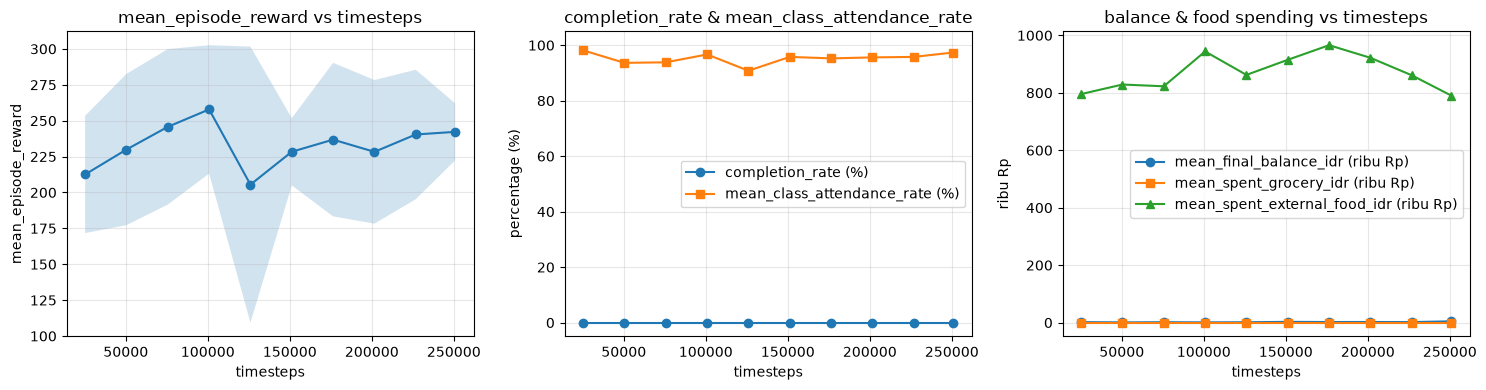

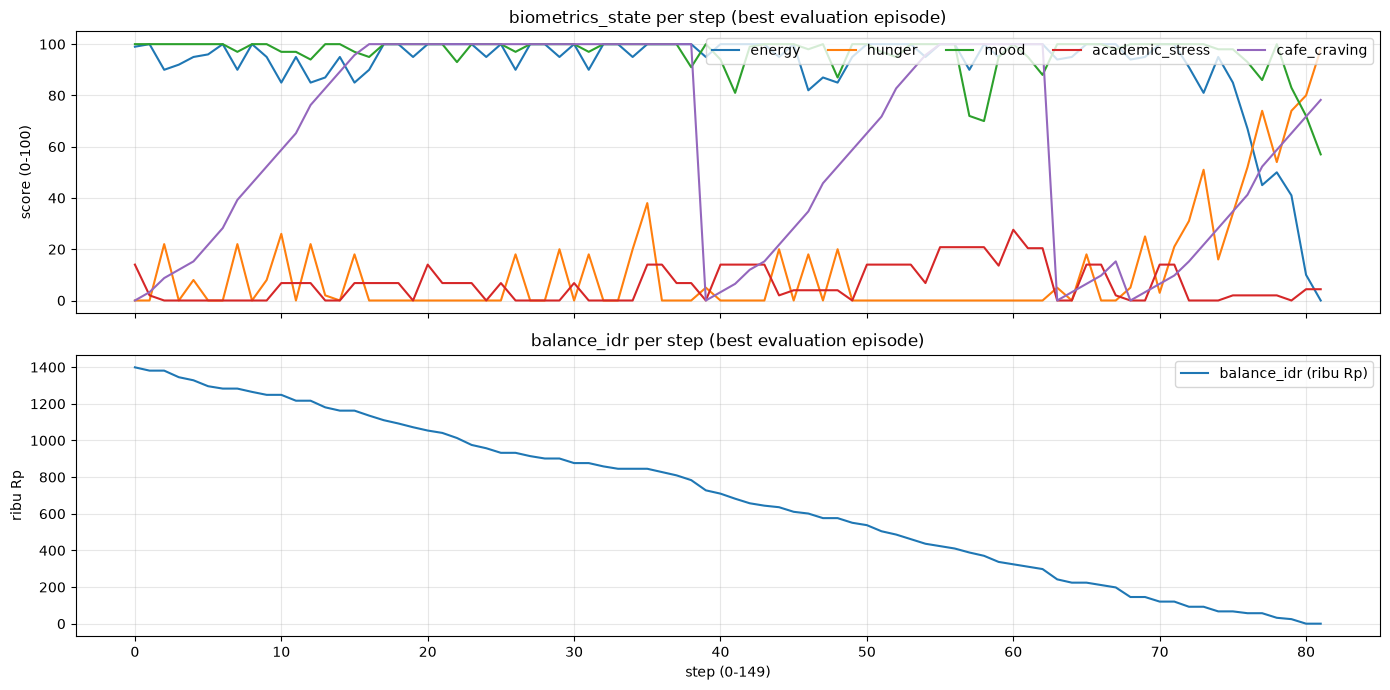

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(eval_history_df["timesteps"], eval_history_df["mean_episode_reward"], marker="o")
axes[0].fill_between(
    eval_history_df["timesteps"],
    eval_history_df["mean_episode_reward"] - eval_history_df["std_episode_reward"],
    eval_history_df["mean_episode_reward"] + eval_history_df["std_episode_reward"],
    alpha=0.2,
)
axes[0].set_title("mean_episode_reward vs timesteps")
axes[0].set_xlabel("timesteps")
axes[0].set_ylabel("mean_episode_reward")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    eval_history_df["timesteps"],
    eval_history_df["completion_rate"] * 100.0,
    marker="o",
    label="completion_rate (%)",
)
axes[1].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_class_attendance_rate"] * 100.0,
    marker="s",
    label="mean_class_attendance_rate (%)",
)
axes[1].set_title("completion_rate & mean_class_attendance_rate")
axes[1].set_xlabel("timesteps")
axes[1].set_ylabel("percentage (%)")
axes[1].set_ylim(-5, 105)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_final_balance_idr"] / 1_000.0,
    marker="o",
    label="mean_final_balance_idr (ribu Rp)",
)
axes[2].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_spent_grocery_idr"] / 1_000.0,
    marker="s",
    label="mean_spent_grocery_idr (ribu Rp)",
)
axes[2].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_spent_external_food_idr"] / 1_000.0,
    marker="^",
    label="mean_spent_external_food_idr (ribu Rp)",
)
axes[2].set_title("balance & food spending vs timesteps")
axes[2].set_xlabel("timesteps")
axes[2].set_ylabel("ribu Rp")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

if not best_episode_trace_df.empty:
    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

    for column_name in ["energy", "hunger", "mood", "academic_stress", "cafe_craving"]:
        axes[0].plot(best_episode_trace_df["step"], best_episode_trace_df[column_name], label=column_name)
    axes[0].set_title("biometrics_state per step (best evaluation episode)")
    axes[0].set_ylabel("score (0-100)")
    axes[0].set_ylim(-5, 105)
    axes[0].legend(ncol=5, loc="upper right")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        best_episode_trace_df["step"],
        best_episode_trace_df["balance_idr"] / 1_000.0,
        label="balance_idr (ribu Rp)",
    )
    axes[1].set_title("balance_idr per step (best evaluation episode)")
    axes[1].set_xlabel("step (0-149)")
    axes[1].set_ylabel("ribu Rp")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

## 5. Trace Detail Episode Terbaik (Hari 1 s/d Hari 30: 5 Step per Hari)

In [20]:
if "run_dir" not in globals():
    run_folders = sorted(
        [path for path in Path(RUNS_ROOT_DIR).iterdir() if path.is_dir()],
        key=lambda path: path.name,
    )
    assert run_folders, "Belum ada folder run di dalam direktori runs/."
    run_dir = run_folders[-1]

best_trace_csv_path = run_dir / "best_episode_trace.csv"
if best_trace_csv_path.exists():
    best_episode_trace_df = pd.read_csv(best_trace_csv_path)
else:
    episodes_table = pd.read_csv(run_dir / "final_eval_episodes.csv")
    best_episode_row = episodes_table.loc[episodes_table["episode_reward"].idxmax()]
    loaded_best_agent = StudentPPOAgent.load_from_run(run_dir, checkpoint="best")
    best_episode_trace_df = loaded_best_agent.record_episode_trace(
        episode_seed=int(best_episode_row["episode_seed"]),
        deterministic=True,
    )
    best_episode_trace_df.to_csv(best_trace_csv_path, index=False)

print(
    f"Run: {run_dir.name} | "
    f"Seed episode terbaik: {int(best_episode_trace_df['episode_seed'].iloc[0])} | "
    f"Total step: {len(best_episode_trace_df)} | "
    f"Total reward: {best_episode_trace_df['cumulative_reward'].iloc[-1]:.2f}"
)

detailed_columns = [
    "day",
    "day_name",
    "time_slot",
    "hours",
    "class_scheduled",
    "location_before",
    "location_after",
    "executed_route",
    "executed_activity",
    "executed_meal_mode",
    "meal_signature",
    "purchased_groceries",
    "step_spend_idr",
    "balance_idr",
    "energy",
    "hunger",
    "mood",
    "academic_stress",
    "cafe_craving",
    "rice_stock",
    "egg_stock",
    "chicken_stock",
    "tempe_stock",
    "meal_prep_stock",
    "packed_lunch_stock",
    "events_summary",
    "step_reward",
    "cumulative_reward",
]

with pd.option_context(
    "display.max_rows", 160,
    "display.max_columns", 40,
    "display.width", 280,
    "display.max_colwidth", 65,
):
    display(best_episode_trace_df[detailed_columns].round({
        "step_spend_idr": 0,
        "balance_idr": 0,
        "energy": 1,
        "hunger": 1,
        "mood": 1,
        "academic_stress": 1,
        "cafe_craving": 1,
        "step_reward": 2,
        "cumulative_reward": 2,
    }))

daily_summary_df = (
    best_episode_trace_df.groupby(["day", "day_name"], sort=True)
    .agg(
        total_spend_idr=("step_spend_idr", "sum"),
        end_balance_idr=("balance_idr", "last"),
        routes_used=("executed_route", lambda s: ", ".join(r for r in s if r != "stay") or "stay"),
        activities=("executed_activity", lambda s: " -> ".join(s)),
        meals=("executed_meal_mode", lambda s: ", ".join(m for m in s if m != "skip") or "skip"),
        mean_energy=("energy", "mean"),
        mean_mood=("mood", "mean"),
        mean_stress=("academic_stress", "mean"),
        daily_reward=("step_reward", "sum"),
    )
    .reset_index()
)

with pd.option_context("display.max_rows", 35, "display.max_columns", 20, "display.width", 260, "display.max_colwidth", 90):
    display(daily_summary_df.round({
        "total_spend_idr": 0,
        "end_balance_idr": 0,
        "mean_energy": 1,
        "mean_mood": 1,
        "mean_stress": 1,
        "daily_reward": 2,
    }))

Run: 20261125_235830_maskable_ppo_5step_unified_budget_38a0e737 | Seed episode terbaik: 11004 | Total step: 82 | Total reward: 330.15


,day,day_name,time_slot,hours,class_scheduled,location_before,location_after,executed_route,executed_activity,executed_meal_mode,meal_signature,purchased_groceries,step_spend_idr,balance_idr,energy,hunger,mood,academic_stress,cafe_craving,rice_stock,egg_stock,chicken_stock,tempe_stock,meal_prep_stock,packed_lunch_stock,events_summary,step_reward,cumulative_reward
0,1,monday,pagi_awal,06:00-09:30,False,apartment,apartment,stay,cafe_session,warung_hemat,warung_hemat,NaN,66078.0,1398922.0,99.0,0.0,100.0,14.0,0.0,0,0,0,0,0,0,"new_daily_task | cafe_total_Rp53,078",5.49,5.49
1,1,monday,sesi_1,09:30-12:15,False,apartment,apartment,stay,room_study,warung_variasi,warung_variasi,NaN,18000.0,1380922.0,100.0,0.0,100.0,2.0,3.2,0,0,0,0,0,0,NaN,5.93,11.42
2,1,monday,sesi_2,12:15-15:15,False,apartment,apartment,stay,room_study,skip,NaN,NaN,0.0,1380922.0,90.0,22.0,100.0,0.0,8.8,0,0,0,0,0,0,NaN,5.25,16.67
3,1,monday,sesi_3,15:15-18:30,True,apartment,campus,transit_ccws_ojol,attend_class,warung_hemat,warung_hemat,NaN,35908.0,1345014.0,92.0,0.0,100.0,0.0,12.0,0,0,0,0,0,0,transit_minimarket_impulse,10.84,27.51
4,1,monday,malam,18:30-22:30,False,campus,apartment,transit_ccws_ojol,room_study,skip,NaN,NaN,16782.0,1328232.0,95.0,8.0,100.0,0.0,15.2,0,0,0,0,0,0,transit_minimarket_impulse,5.70,33.21
5,2,tuesday,pagi_awal,06:00-09:30,False,apartment,campus,transit_ccws_ojol,ccws_stay,craving_snack,craving_snack,NaN,32336.0,1295896.0,96.0,0.0,100.0,0.0,21.8,0,0,0,0,0,0,new_daily_task,5.92,39.13
6,2,tuesday,sesi_1,09:30-12:15,True,campus,campus,stay,attend_class,warung_hemat,warung_hemat,NaN,13000.0,1282896.0,100.0,0.0,100.0,0.0,28.2,0,0,0,0,0,0,NaN,11.00,50.13
7,2,tuesday,sesi_2,12:15-15:15,True,campus,campus,stay,attend_class,skip,NaN,NaN,0.0,1282896.0,90.0,22.0,97.0,0.0,39.2,0,0,0,0,0,0,distracted_craving,10.16,60.29
8,2,tuesday,sesi_3,15:15-18:30,True,campus,campus,stay,attend_class,warung_variasi,warung_variasi,NaN,18000.0,1264896.0,100.0,0.0,100.0,0.0,45.8,0,0,0,0,0,0,distracted_craving,11.00,71.29
9,2,tuesday,malam,18:30-22:30,False,campus,apartment,transit_ccws_ojol,room_study,skip,NaN,NaN,16111.0,1248785.0,95.0,8.0,100.0,0.0,52.2,0,0,0,0,0,0,transit_minimarket_impulse | distracted_craving,5.70,76.99


,day,day_name,total_spend_idr,end_balance_idr,routes_used,activities,meals,mean_energy,mean_mood,mean_stress,daily_reward
0,1,monday,136768.0,1328232.0,"transit_ccws_ojol, transit_ccws_ojol",cafe_session -> room_study -> room_study -> attend_class -> room_study,"warung_hemat, warung_variasi, warung_hemat",95.2,100.0,3.2,33.21
1,2,tuesday,79447.0,1248785.0,"transit_ccws_ojol, transit_ccws_ojol",ccws_stay -> attend_class -> attend_class -> attend_class -> room_study,"craving_snack, warung_hemat, warung_variasi",96.2,99.4,0.0,43.78
2,3,wednesday,86162.0,1162623.0,"direct_ojol, direct_ojol",room_study -> attend_class -> attend_class -> room_study -> rest_or_sleep,"warung_variasi, craving_snack, warung_variasi",89.4,97.6,4.1,36.62
3,4,thursday,90601.0,1072022.0,"transit_ccws_ojol, transit_ccws_ojol",room_study -> attend_class -> wait_at_department -> attend_class -> room_study,"warung_variasi, craving_snack, warung_variasi, warung_hemat",94.0,98.4,5.4,37.76
4,5,friday,114587.0,957435.0,"direct_ojol, direct_ojol",rest_or_sleep -> room_study -> attend_class -> rest_or_sleep -> room_study,"warung_variasi, warung_hemat, warung_hemat, craving_snack, warung_variasi",99.0,98.6,6.9,33.49
5,6,saturday,56000.0,901435.0,stay,room_study -> room_study -> rest_or_sleep -> room_study -> room_study,"craving_snack, warung_variasi, warung_hemat",97.0,99.4,1.4,28.42
6,7,sunday,56000.0,845435.0,stay,room_study -> room_study -> rest_or_sleep -> room_study -> room_study,"craving_snack, warung_variasi, warung_hemat",97.0,99.4,1.4,28.42
7,8,monday,117711.0,727724.0,"transit_ccws_ojol, direct_ojol",rest_or_sleep -> rest_or_sleep -> room_study -> attend_class -> cafe_session,"warung_variasi, warung_variasi, warung_variasi",99.0,98.2,8.3,32.10
8,9,tuesday,92071.0,635653.0,"transit_ccws_ojol, transit_ccws_ojol",rest_or_sleep -> attend_class -> attend_class -> attend_class -> room_study,"warung_variasi, warung_variasi, craving_snack, warung_hemat",99.0,94.8,11.6,41.59
9,10,wednesday,84898.0,550755.0,"transit_ccws_ojol, transit_ccws_ojol",room_study -> attend_class -> attend_class -> wait_at_department -> room_study,"craving_snack, craving_snack, warung_variasi",89.8,97.0,3.2,37.02


## 6. Perbandingan Antar-Eksperimen & Reproduksi dari Snapshot Run

In [21]:
master_summary_path = Path(RUNS_ROOT_DIR) / "experiments_summary.csv"
if master_summary_path.exists():
    experiments_df = pd.read_csv(master_summary_path)
    preferred_cols = [
        "run_id",
        "experiment_name",
        "env_config_sha256",
        "use_action_masking",
        "seed",
        "total_timesteps",
        "best_checkpoint_timestep",
        "mean_episode_reward",
        "completion_rate",
        "mean_class_attendance_rate",
        "mean_final_balance_idr",
        "mean_spent_transport_idr",
        "mean_spent_grocery_idr",
        "mean_spent_external_food_idr",
        "mean_spent_cafe_idr",
        "mean_cook_fresh_count",
        "mean_eat_bekal_count",
        "mean_spoiled_units",
    ]
    available_cols = [col for col in preferred_cols if col in experiments_df.columns]
    display(experiments_df[available_cols].sort_values(by="mean_episode_reward", ascending=False))

reloaded_agent = StudentPPOAgent.load_from_run(run_dir, checkpoint="best")
recheck_summary, _, _ = reloaded_agent.evaluate_detailed(
    num_episodes=TRAINING_SCHEDULE["final_eval_episodes"],
    deterministic=True,
    eval_seed=TRAINING_SCHEDULE["eval_seed"] + 10_000,
)
print(
    "Verifikasi reload dari snapshot:",
    f"original={final_summary['mean_episode_reward']:.4f}",
    f"| reloaded={recheck_summary['mean_episode_reward']:.4f}",
)

,run_id,experiment_name,env_config_sha256,use_action_masking,seed,total_timesteps,best_checkpoint_timestep,mean_episode_reward,completion_rate,mean_class_attendance_rate,mean_final_balance_idr,mean_spent_transport_idr,mean_spent_grocery_idr,mean_spent_external_food_idr,mean_spent_cafe_idr,mean_cook_fresh_count,mean_eat_bekal_count,mean_spoiled_units
0,20261125_221435_ppo_residual_baseline_8983b576,ppo_residual_baseline,8983b576c5c5,NaN,42,200640,120960,906.743232,1.00,1.000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0
1,20261125_224522_ppo_residual_baseline_fe81d6e5,ppo_residual_baseline,fe81d6e54004,NaN,42,200640,161280,749.288246,0.75,1.000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0
2,20261125_231931_ppo_residual_baseline_4c381550,ppo_residual_baseline,4c381550abe4,NaN,42,200640,161280,485.191304,0.00,0.998684,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0
3,20261125_233008_ppo_residual_baseline_deb8b2a4,ppo_residual_baseline,deb8b2a4c0f0,NaN,42,200640,141120,474.236099,0.00,1.000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0
4,20261125_235830_maskable_ppo_5step_unified_bud...,maskable_ppo_5step_unified_budget,38a0e737ecc9,True,42,250800,100800,240.127953,0.00,0.945854,1251.5,273995.35,0.0,970600.0,126731.0,0.0,0.0,0.0


Verifikasi reload dari snapshot: original=240.1280 | reloaded=240.1280
